# Submission 4: Custom CNN with an attention module
**Dataset:** SCAB benchmark (original images, Scabies vs Healthy)
**Baseline:** the custom CNN from Submission 3
**Attention model:** the same CNN with one SE (squeeze-and-excitation) block after the last conv block, nothing else changed
**Outputs:** curves, classification report, confusion matrix, training and testing time, baseline vs attention table

## 0. Colab setup
Mounts Google Drive and unzips the images. `SCAB_original.zip` and `SCAB_metadata_CSV.csv` must be in the top level of My Drive.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!rm -rf /content/data
!mkdir -p /content/data
!unzip -q "/content/drive/MyDrive/SCAB_original.zip" -d /content/data
!ls /content/data

Mounted at /content/drive
SCAB_original


## 1. Imports

In [2]:
import os, time, random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers, models, callbacks

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Settings
Same as Submission 3 for both models: batch size 32, Adam, learning rate 1e-3, at most 50 epochs, same seed.

In [3]:
DATA_ROOT = '/content/data'
CSV_PATH = '/content/drive/MyDrive/SCAB_metadata_CSV.csv'

IMG = 224
BATCH = 32
EPOCHS = 50
PATIENCE = 8
LR = 1e-3
CLASS_NAMES = ['Healthy', 'Scabies']

## 3. Match the CSV to the image files
Same as Submissions 2 and 3.

In [4]:
index = {}
for root, dirs, files in os.walk(DATA_ROOT):
    if '__MACOSX' in root:
        continue
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')) and not f.startswith('._'):
            index[f] = os.path.join(root, f)
print('Images found in zip:', len(index))

df = pd.read_csv(CSV_PATH)
df = df.dropna(subset=['Image_id'])
df = df[['Image_id', 'Class Label']].copy()
df.columns = ['image', 'class_name']

df['patient'] = df['image'].str.extract(r'^(PAT_\d+)')[0]
df['label'] = (df['class_name'] == 'Scabies').astype(int)
df['path'] = df['image'].map(index)
df['folder'] = df['path'].map(lambda p: os.path.basename(os.path.dirname(p)) if isinstance(p, str) else None)

print('Total images in CSV:', len(df))
print('Missing files:', df['path'].isna().sum())
assert df['path'].notna().all(), 'Some CSV images were not found in the unzipped folder'
pd.crosstab(df['folder'], df['class_name'])

Images found in zip: 606
Total images in CSV: 606
Missing files: 0


class_name,Healthy,Scabies
folder,,
Scabies,0,406
healthy,200,0


## 4. Train / validation / test split (by patient)
Same split as Submissions 2 and 3.

In [5]:
patients = df.groupby('patient', as_index=False)['label'].first()

train_p, temp_p = train_test_split(patients, test_size=0.30, stratify=patients['label'], random_state=SEED)
val_p, test_p = train_test_split(temp_p, test_size=0.50, stratify=temp_p['label'], random_state=SEED)

train_df = df[df['patient'].isin(train_p['patient'])]
val_df = df[df['patient'].isin(val_p['patient'])]
test_df = df[df['patient'].isin(test_p['patient'])]

summary = pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test'],
    'Patients': [len(train_p), len(val_p), len(test_p)],
    'Images': [len(train_df), len(val_df), len(test_df)],
    'Healthy': [(d['label'] == 0).sum() for d in (train_df, val_df, test_df)],
    'Scabies': [(d['label'] == 1).sum() for d in (train_df, val_df, test_df)],
})
print('Patient overlap train/test:', len(set(train_p['patient']) & set(test_p['patient'])))
summary

Patient overlap train/test: 0


,Split,Patients,Images,Healthy,Scabies
0,Train,118,423,140,283
1,Validation,25,92,27,65
2,Test,26,91,33,58


## 5. Build the data pipelines
Same as Submission 3.

In [6]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    return img, tf.cast(label, tf.float32)

def make_ds(d, train=False):
    ds = tf.data.Dataset.from_tensor_slices((d['path'].values, d['label'].values))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if train:
        ds = ds.shuffle(len(d), seed=SEED)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_df, train=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

y_train = train_df['label'].values
y_test = test_df['label'].values

weights = len(y_train) / (2 * np.bincount(y_train))
class_weight = {0: weights[0], 1: weights[1]}
print('Class weights:', class_weight)

Class weights: {0: np.float64(1.5107142857142857), 1: np.float64(0.7473498233215548)}


## 6. Baseline CNN and CNN with attention
The SE block gives each channel a weight between 0 and 1 and multiplies the feature map by it: global average pooling, Dense (channels/8, ReLU), Dense (channels, sigmoid), multiply. The only difference between the two models is `attention=True`, which adds one SE block after the last conv block.

In [7]:
augment = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

def se_block(x, ratio=8):
    channels = x.shape[-1]
    s = layers.GlobalAveragePooling2D()(x)
    s = layers.Dense(channels // ratio, activation='relu')(s)
    s = layers.Dense(channels, activation='sigmoid')(s)
    s = layers.Reshape((1, 1, channels))(s)
    return layers.Multiply()([x, s])

def build_cnn(attention=False):
    inputs = layers.Input((IMG, IMG, 3))
    x = augment(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for f in [32, 64, 128, 256]:
        x = conv_block(x, f)
    if attention:
        x = se_block(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = models.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(LR), loss='binary_crossentropy', metrics=['accuracy'])
    return model

print('Baseline parameters:', build_cnn(False).count_params())
print('Attention parameters:', build_cnn(True).count_params())

Baseline parameters: 423361
Attention parameters: 440033


## 7. Train and evaluate
Same function for both models, same early stopping as Submission 3.

In [8]:
def run(title, attention):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_cnn(attention)
    cbs = [callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, start_from_epoch=5, restore_best_weights=True)]

    start = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                     class_weight=class_weight, callbacks=cbs, verbose=2)
    train_seconds = time.time() - start

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist.history['accuracy'], label='Train')
    ax[0].plot(hist.history['val_accuracy'], label='Validation')
    ax[0].set_title(f'{title}: Accuracy')
    ax[0].set_xlabel('Epoch')
    ax[0].set_ylabel('Accuracy')
    ax[0].legend()
    ax[1].plot(hist.history['loss'], label='Train')
    ax[1].plot(hist.history['val_loss'], label='Validation')
    ax[1].set_title(f'{title}: Loss')
    ax[1].set_xlabel('Epoch')
    ax[1].set_ylabel('Loss')
    ax[1].legend()
    plt.tight_layout()
    plt.show()

    start = time.time()
    y_prob = model.predict(test_ds, verbose=0).ravel()
    test_seconds = time.time() - start
    y_pred = (y_prob > 0.5).astype(int)

    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap='Blues')
    plt.title(f'{title}: Test confusion matrix')
    plt.show()

    rep = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    return {
        'Model': title,
        'Epochs Run': len(hist.history['loss']),
        'Parameters': model.count_params(),
        'Test Acc': round(rep['accuracy'], 4),
        'Precision': round(rep['macro avg']['precision'], 4),
        'Recall': round(rep['macro avg']['recall'], 4),
        'F1': round(rep['macro avg']['f1-score'], 4),
        'Train Time (min)': round(train_seconds / 60, 2),
        'Test Time (sec)': round(test_seconds, 2),
    }

## 8. Run both models

### 8.1 Baseline CNN (no attention)

Epoch 1/50
14/14 - 20s - 1s/step - accuracy: 0.8227 - loss: 0.3780 - val_accuracy: 0.7065 - val_loss: 0.5809
Epoch 2/50
14/14 - 2s - 136ms/step - accuracy: 0.8913 - loss: 0.2514 - val_accuracy: 0.9022 - val_loss: 0.3058
Epoch 3/50
14/14 - 2s - 130ms/step - accuracy: 0.9102 - loss: 0.2022 - val_accuracy: 0.8913 - val_loss: 0.2664
Epoch 4/50
14/14 - 2s - 131ms/step - accuracy: 0.9385 - loss: 0.1699 - val_accuracy: 0.9130 - val_loss: 0.1973
Epoch 5/50
14/14 - 2s - 140ms/step - accuracy: 0.9433 - loss: 0.1371 - val_accuracy: 0.9674 - val_loss: 0.1032
Epoch 6/50
14/14 - 3s - 180ms/step - accuracy: 0.9243 - loss: 0.1674 - val_accuracy: 0.4239 - val_loss: 2.4970
Epoch 7/50
14/14 - 2s - 135ms/step - accuracy: 0.9598 - loss: 0.1264 - val_accuracy: 0.7826 - val_loss: 0.7037
Epoch 8/50
14/14 - 2s - 140ms/step - accuracy: 0.9173 - loss: 0.1821 - val_accuracy: 0.9130 - val_loss: 0.2034
Epoch 9/50
14/14 - 2s - 138ms/step - accuracy: 0.9504 - loss: 0.1125 - val_accuracy: 0.9674 - val_loss: 0.1687
Epo

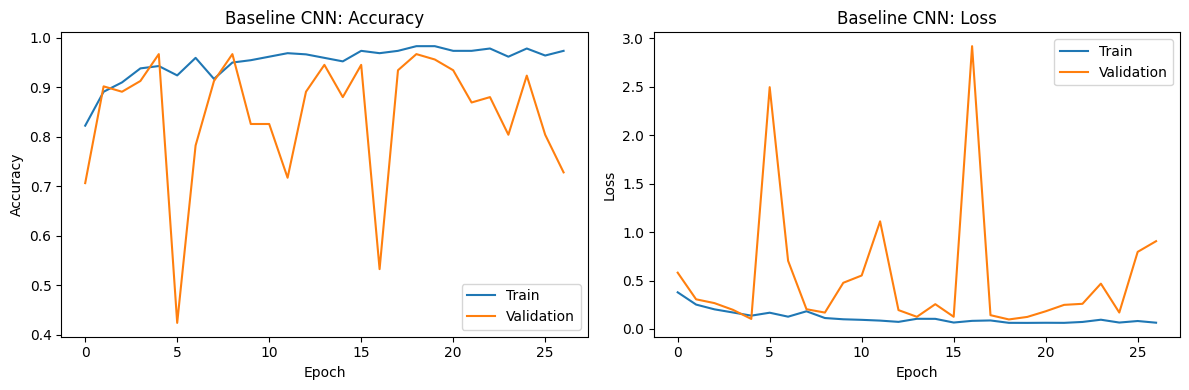

              precision    recall  f1-score   support

     Healthy     0.8684    1.0000    0.9296        33
     Scabies     1.0000    0.9138    0.9550        58

    accuracy                         0.9451        91
   macro avg     0.9342    0.9569    0.9423        91
weighted avg     0.9523    0.9451    0.9458        91



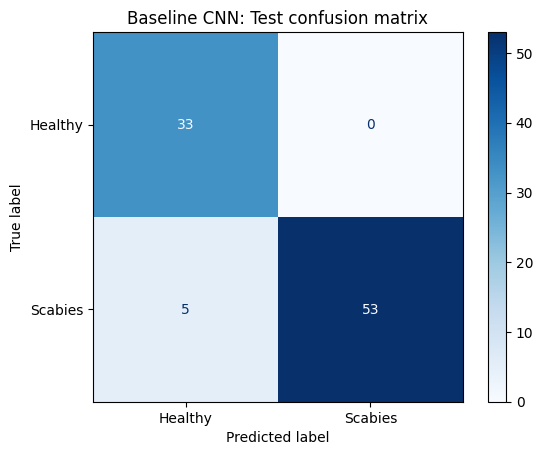

In [9]:
results = []
results.append(run('Baseline CNN', attention=False))

### 8.2 CNN with SE attention

Epoch 1/50
14/14 - 7s - 493ms/step - accuracy: 0.8463 - loss: 0.2834 - val_accuracy: 0.7065 - val_loss: 0.5557
Epoch 2/50
14/14 - 2s - 136ms/step - accuracy: 0.9220 - loss: 0.1929 - val_accuracy: 0.8913 - val_loss: 0.3665
Epoch 3/50
14/14 - 2s - 135ms/step - accuracy: 0.9220 - loss: 0.1893 - val_accuracy: 0.7065 - val_loss: 0.3803
Epoch 4/50
14/14 - 2s - 135ms/step - accuracy: 0.9149 - loss: 0.1939 - val_accuracy: 0.8804 - val_loss: 0.1764
Epoch 5/50
14/14 - 2s - 135ms/step - accuracy: 0.9456 - loss: 0.1522 - val_accuracy: 0.9674 - val_loss: 0.1183
Epoch 6/50
14/14 - 2s - 140ms/step - accuracy: 0.9291 - loss: 0.1503 - val_accuracy: 0.8370 - val_loss: 0.3455
Epoch 7/50
14/14 - 2s - 139ms/step - accuracy: 0.9291 - loss: 0.1448 - val_accuracy: 0.5435 - val_loss: 2.6227
Epoch 8/50
14/14 - 2s - 143ms/step - accuracy: 0.9433 - loss: 0.1039 - val_accuracy: 0.9022 - val_loss: 0.2611
Epoch 9/50
14/14 - 2s - 140ms/step - accuracy: 0.9574 - loss: 0.1254 - val_accuracy: 0.9674 - val_loss: 0.0803
E

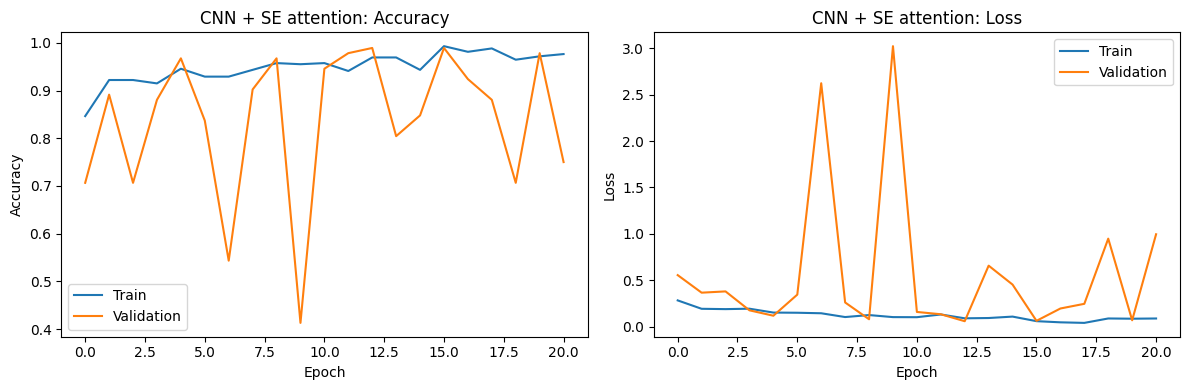

              precision    recall  f1-score   support

     Healthy     0.8049    1.0000    0.8919        33
     Scabies     1.0000    0.8621    0.9259        58

    accuracy                         0.9121        91
   macro avg     0.9024    0.9310    0.9089        91
weighted avg     0.9292    0.9121    0.9136        91



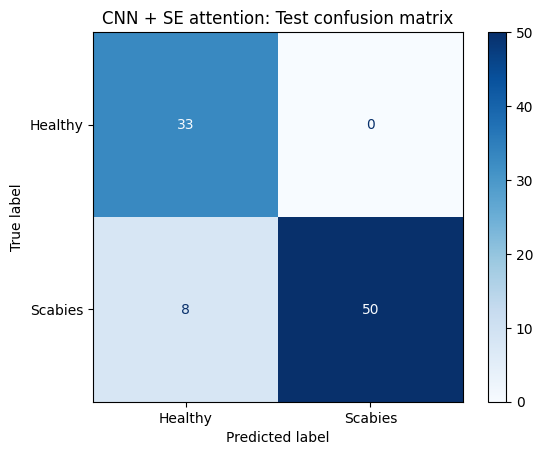

In [10]:
results.append(run('CNN + SE attention', attention=True))

## 9. Comparison
The last row is attention minus baseline.

In [11]:
results_df = pd.DataFrame(results).set_index('Model')
diff = results_df.loc['CNN + SE attention'] - results_df.loc['Baseline CNN']
results_df.loc['Difference'] = diff.round(4)
results_df

,Epochs Run,Parameters,Test Acc,Precision,Recall,F1,Train Time (min),Test Time (sec)
Model,,,,,,,,
Baseline CNN,27.0,423361.0,0.9451,0.9342,0.9569,0.9423,1.16,1.38
CNN + SE attention,21.0,440033.0,0.9121,0.9024,0.9310,0.9089,0.77,0.62
Difference,-6.0,16672.0,-0.0330,-0.0318,-0.0259,-0.0334,-0.39,-0.76


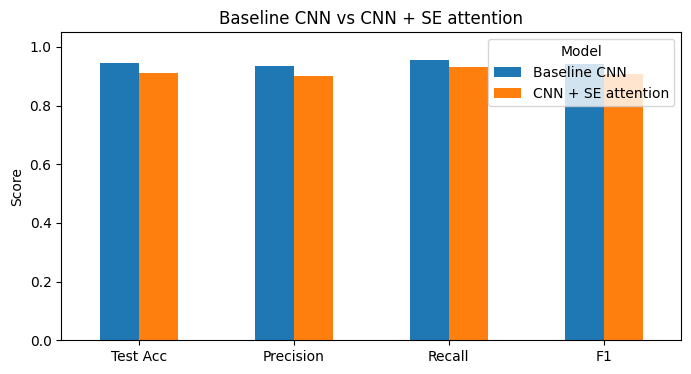

In [12]:
metrics = ['Test Acc', 'Precision', 'Recall', 'F1']
results_df.loc[['Baseline CNN', 'CNN + SE attention'], metrics].T.plot(kind='bar', figsize=(8, 4), ylim=(0, 1.05))
plt.title('Baseline CNN vs CNN + SE attention')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.show()

## 10. Conclusion
The SE attention block did not improve the results. The baseline CNN got a test accuracy of 0.9451, precision 0.9342, recall 0.9569 and F1 0.9423. The CNN with attention got 0.9121, 0.9024, 0.9310 and 0.9089. Both models got all 33 Healthy images right, but the baseline missed 5 of the 58 Scabies images and the attention model missed 8. Attention added 16,672 parameters (440,033 compared with 423,361).

Training stopped at epoch 27 for the baseline and at epoch 21 for the attention model, which explains the shorter training time (0.77 against 1.16 minutes). The test time difference (0.62 against 1.38 seconds) is too small to mean anything, and the baseline ran first so its time includes warm-up. We do not claim that attention made the model faster.

The gap of 3 images between the two models is small. GPU training is not exactly repeatable, and across our runs the same baseline CNN scored anywhere from 0.9231 to 0.9670 on the test set. So we cannot say that attention hurts, but we found no sign that it helps on this dataset. A fairer test would average several runs of each model.

Limitations: the test set has only 91 images, so one image changes accuracy by about 1.1 points. The Healthy and Scabies photos were taken in different settings, so both models may partly use the background. These scores should not be read as clinical performance.